In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

In [3]:
data = load_breast_cancer()

In [9]:
x = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

print(x.head())
print(x.shape)
print(x.info())
print(x.isnull().sum())

   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst radius  worst texture  worst perimeter  \
0           

In [11]:
x_train, x_test, y_train, y_test = train_test_split(
    x, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [12]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(x_train)
X_test_scaled = scaler.transform(x_test)

In [13]:
pca = PCA()

X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

In [14]:
print(pca.explained_variance_ratio_)

[4.44134918e-01 1.89446183e-01 9.54335633e-02 6.72468941e-02
 5.51769040e-02 3.93453424e-02 2.18176591e-02 1.58331722e-02
 1.27878330e-02 1.14544250e-02 9.26269214e-03 8.47428916e-03
 7.99746679e-03 5.30706257e-03 3.12250212e-03 2.57146110e-03
 2.03925720e-03 1.86696858e-03 1.49100638e-03 1.03671459e-03
 9.25703045e-04 8.66421035e-04 7.19778970e-04 5.88332657e-04
 5.04652748e-04 2.45507775e-04 2.16103111e-04 5.71732867e-05
 2.57352579e-05 4.27774949e-06]


In [15]:
cumulative_variance = np.cumsum(
    pca.explained_variance_ratio_
)

print(cumulative_variance)

[0.44413492 0.6335811  0.72901466 0.79626156 0.85143846 0.8907838
 0.91260146 0.92843464 0.94122247 0.95267689 0.96193959 0.97041388
 0.97841134 0.9837184  0.98684091 0.98941237 0.99145162 0.99331859
 0.9948096  0.99584631 0.99677202 0.99763844 0.99835822 0.99894655
 0.9994512  0.99969671 0.99991281 0.99996999 0.99999572 1.        ]


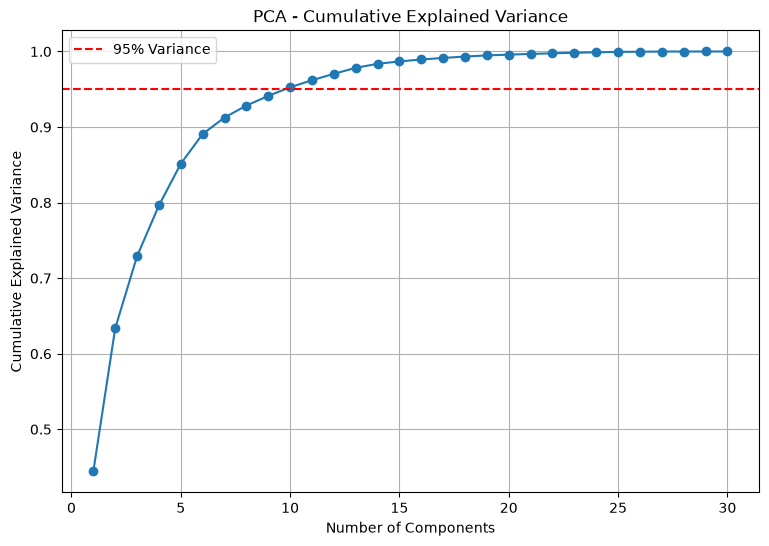

In [16]:
plt.figure(figsize=(9, 6))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker='o'
)

plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('PCA - Cumulative Explained Variance')

plt.axhline(
    y=0.95,
    color='red',
    linestyle='--',
    label='95% Variance'
)

plt.legend()
plt.grid()
plt.show()

In [17]:
pca = PCA(n_components=0.95)

X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

In [18]:
print("Original shape:", X_train_scaled.shape)
print("Reduced shape:", X_train_pca.shape)

print("Components:", pca.n_components_)
print(
    "Variance retained:",
    pca.explained_variance_ratio_.sum()
)

Original shape: (455, 30)
Reduced shape: (455, 10)
Components: 10
Variance retained: 0.9526768937417547


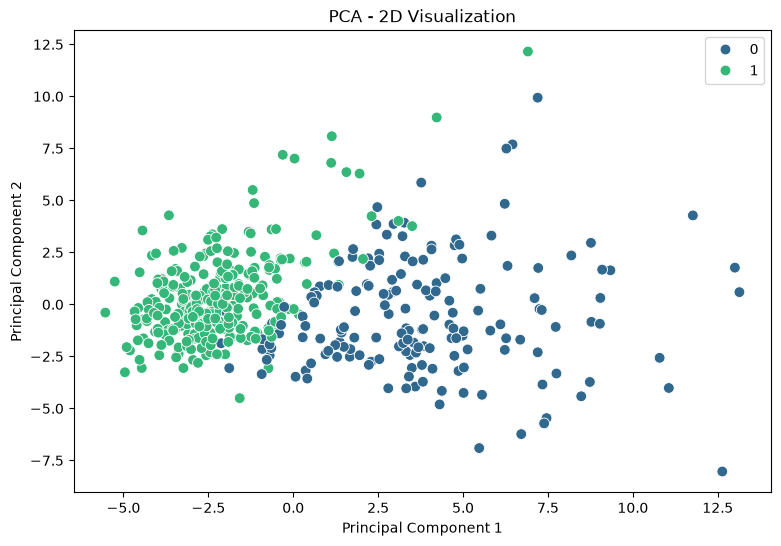

In [19]:
pca_2d = PCA(n_components=2)

X_2d = pca_2d.fit_transform(X_train_scaled)

plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=X_2d[:, 0],
    y=X_2d[:, 1],
    hue=y_train,
    palette='viridis',
    s=60
)

plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('PCA - 2D Visualization')

plt.show()

In [20]:
model = LogisticRegression(max_iter=1000)

model.fit(X_train_pca, y_train)

y_pred = model.predict(X_test_pca)

print("Accuracy:", accuracy_score(y_test, y_pred))

print(classification_report(y_test, y_pred))

Accuracy: 0.9736842105263158
              precision    recall  f1-score   support

           0       0.95      0.98      0.96        42
           1       0.99      0.97      0.98        72

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



In [22]:
results = pd.DataFrame({
    "precited" : y_pred,
    "actual" : y_test
})
print(results)

     precited  actual
0           0       0
1           1       1
2           0       0
3           1       1
4           0       0
..        ...     ...
109         0       0
110         1       1
111         0       0
112         1       1
113         1       1

[114 rows x 2 columns]
